# ITCS 6169/8169 — Computer Vision
## Assignment 2: SSL

In [3]:
# Core imports
from pathlib import Path
import random
import time
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import torch_directml # to allow for AMD gpu usage

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.4.1+cpu
CUDA available: False


In [4]:
# CHANGE THIS PATH to your own assignment directory.
# Example for Colab + Google Drive:
# PROJECT_ROOT = Path('/content/gdrive/MyDrive/ITCS_6169_8169/assignment1')

PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment2
Training data: data\train
Testing data: data\test


In [5]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_random_seed(SEED)
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = torch_directml.device() # Set device to AMD GPU via DirectML
print('Using device:', device)

Using device: privateuseone:0


In [6]:
IMG_SIZE = 128
BATCH_SIZE = 32
VAL_FRACTION = 0.20

# Mixup helper function
def mixup_data(x, y, alpha=0.2):
    '''Returns mixed inputs, pairs of targets, and lambda.'''
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)

    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

# cutmix helper function
def cutmix_data(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3)

    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_ratio), int(W * cut_ratio)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)

    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / (H * W))   # correct lam for the clipped box
    return x, y, y[index], lam

# Define the corresponding loss function
def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def random_grayscale_rgb(img):
    # Augment only on training; validation/test should stay clean.
    if random.random() < 0.5:
        gray = img.convert("L")
        return gray.convert("RGB")
    return img

# Training augmentation: random transforms only here.
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    # transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.Lambda(random_grayscale_rgb),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# Validation/test preprocessing: no randomness.
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    # transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image, label = self.subset[idx]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

# Load base dataset once so we can split by index.
base_train_dataset = datasets.ImageFolder(TRAIN_ROOT)
class_names = base_train_dataset.classes
num_classes = len(class_names)

val_size = int(round(len(base_train_dataset) * VAL_FRACTION))
train_size = len(base_train_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    base_train_dataset, [train_size, val_size], generator=generator
)

train_dataset = TransformSubset(train_subset, train_transform)
val_dataset = TransformSubset(val_subset, eval_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=torch.cuda.is_available())

print(f'Classes ({num_classes}): {class_names}')
print(f'Total training images: {len(base_train_dataset)}')
print(f'Test images: {len(test_dataset)}')
print(f'Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')

Classes (16): ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Total training images: 2400
Test images: 400
Train: 1920 | Validation: 480 | Test: 400


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.558952..1.6021352].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.558952..1.7589979].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.45620346..1.7067103].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5418272..1.6544228].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.558952..1.279695].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.48189062..1.5411329].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.558952..

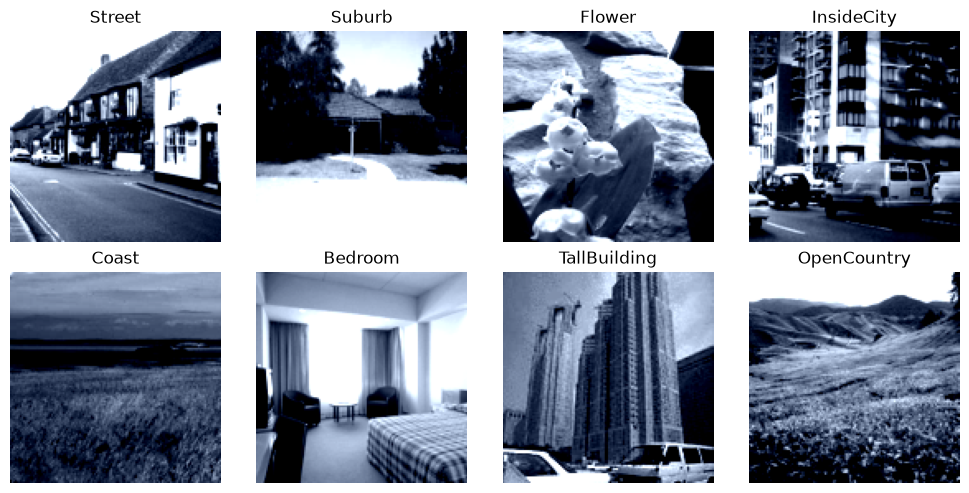

In [7]:
# Visualize a few training examples
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    # Undo normalization for both grayscale (C=1) and RGB (C=3)
    if image.shape[0] == 1:
        image = image[0] * 0.5 + 0.5
        ax.imshow(image.numpy(), cmap='gray')
    else:
        image = image.permute(1, 2, 0)  # HWC
        image = image * 0.5 + 0.5
        ax.imshow(image.numpy())
    ax.set_title(class_names[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
def conv_bn_relu(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )

class TNet(nn.Module):
    def __init__(self, num_classes=16, widths=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = widths

        self.features = nn.Sequential(
            # Stage 1
            conv_bn_relu(3, c1),
            conv_bn_relu(c1, c1),
            nn.MaxPool2d(2),

            # Stage 2
            conv_bn_relu(c1, c2),
            conv_bn_relu(c2, c2),
            nn.MaxPool2d(2),

            # Stage 3 (no pool needed; global average pooling follows)
            conv_bn_relu(c2, c3),
            conv_bn_relu(c3, c3),
            nn.MaxPool2d(2),
            
            conv_bn_relu(c3, c4),
            conv_bn_relu(c4, c4),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c4, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = TNet(num_classes=num_classes)
print(model)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

TNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (4): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True,

In [9]:
# @torch.inference_mode()
@torch.no_grad() # gemini solution for directml
def evaluate(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    running_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, epochs=20, device=device, mixup_alpha=0.0, cutmix_alpha=1.0, cutmix_prob=0.0):
    criterion = nn.CrossEntropyLoss()
    model = model.to(device)
    best_state = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_seen = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            
            # Pick at most one mixing method per batch
            use_cutmix = cutmix_prob > 0 and np.random.rand() < cutmix_prob
            use_mixup = (not use_cutmix) and mixup_alpha > 0

            if use_cutmix:
                images, labels_a, labels_b, lam = cutmix_data(images, labels, alpha=cutmix_alpha)
            elif use_mixup:
                images, labels_a, labels_b, lam = mixup_data(images, labels, alpha=mixup_alpha)

            logits = model(images)
            if use_cutmix or use_mixup:
                # can use mixup_criterion for both mixup and cutmix
                loss = mixup_criterion(criterion, logits, labels_a, labels_b, lam)
            else:
                loss = criterion(logits, labels)
                
                
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_seen += labels.size(0)

        train_loss = total_loss / total_seen
        val_loss, val_acc = evaluate(model, val_loader, device)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        scheduler.step()
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start
        print(f'Epoch {epoch:02d}/{epochs} | '
              f'train loss {train_loss:.4f} | val loss {val_loss:.4f} | '
              f'val acc {val_acc:.4f} | {elapsed:.1f}s')

    last_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    print(f'Best validation accuracy: {best_val_acc:.4f}')
    return model, history, best_state, last_state

In [10]:
# Train the model
epochs = 120
set_random_seed(SEED)
model = TNet(num_classes=num_classes)
model = model.to(device)
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.05)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

model, history, best_state, last_state = train_model(
    model, train_loader, val_loader, optimizer, epochs=epochs, device=device,
    mixup_alpha=0.4, cutmix_alpha=1.0, cutmix_prob=0.5
)

c:\Users\Bryan\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)


Epoch 01/120 | train loss 2.4518 | val loss 1.9786 | val acc 0.3812 | 10.2s
Epoch 02/120 | train loss 2.1832 | val loss 1.8336 | val acc 0.4042 | 18.4s
Epoch 03/120 | train loss 2.0547 | val loss 1.7643 | val acc 0.4125 | 26.7s
Epoch 04/120 | train loss 1.9171 | val loss 1.7858 | val acc 0.3812 | 34.9s
Epoch 05/120 | train loss 1.8285 | val loss 1.3573 | val acc 0.5500 | 43.5s
Epoch 06/120 | train loss 1.8591 | val loss 1.3590 | val acc 0.5542 | 51.9s
Epoch 07/120 | train loss 1.6981 | val loss 1.7924 | val acc 0.3771 | 60.2s
Epoch 08/120 | train loss 1.7759 | val loss 1.3636 | val acc 0.5521 | 68.4s
Epoch 09/120 | train loss 1.6390 | val loss 1.1969 | val acc 0.5958 | 76.4s
Epoch 10/120 | train loss 1.6558 | val loss 1.0799 | val acc 0.6438 | 84.6s
Epoch 11/120 | train loss 1.6097 | val loss 1.5810 | val acc 0.4813 | 92.6s
Epoch 12/120 | train loss 1.5783 | val loss 1.2530 | val acc 0.6000 | 100.8s
Epoch 13/120 | train loss 1.6408 | val loss 1.0540 | val acc 0.6542 | 108.9s
Epoch 14/1

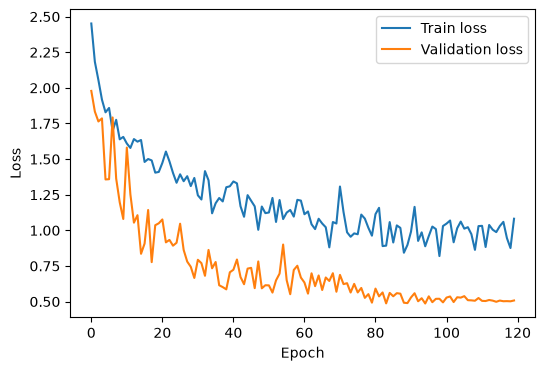

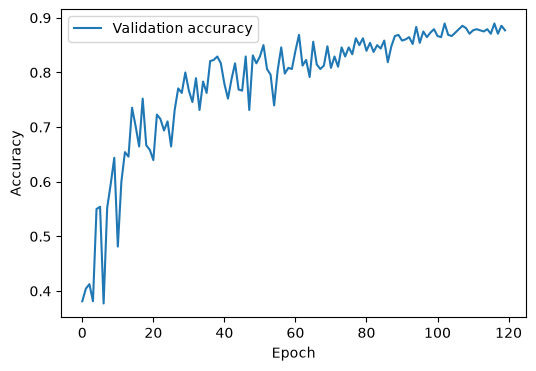

In [11]:
# Plot training history loss and accuracy
plt.figure(figsize=(6, 4))
plt.plot(history['train_loss'], label='Train loss')
plt.plot(history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history['val_acc'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

| Experiment | What changed? | Why did you try it? | Validation accuracy | What did you learn? |
|---|---|---|---:|---|
| Final model from A1 | Nothing | Baseline | 0.8896, 0.8771 (best, last) | N/A |
| Experiment 1 |  |  |  |  |

In [12]:
# evaluate on best state
test_loss, test_acc = evaluate(model, test_loader, device)
print(f'Final test loss: {test_loss:.4f}')
print(f'Final test accuracy: {test_acc:.4f}')

Final test loss: 0.5852
Final test accuracy: 0.8600


Validation overall accuracy: 0.8896

Class             Acc     N   Most confused with
Industrial      0.724    29   Highway
InsideCity      0.733    30   Industrial
LivingRoom      0.769    26   Bedroom
Bedroom         0.795    39   LivingRoom
Kitchen         0.800    30   Bedroom
Store           0.806    31   InsideCity
OpenCountry     0.821    28   Coast
Highway         0.893    28   Coast
Mountain        0.964    28   Industrial
Flower          0.968    31   Mountain
Coast           0.970    33   OpenCountry
Forest          1.000    29   -
Office          1.000    24   -
Street          1.000    32   -
Suburb          1.000    34   -
TallBuilding    1.000    28   -


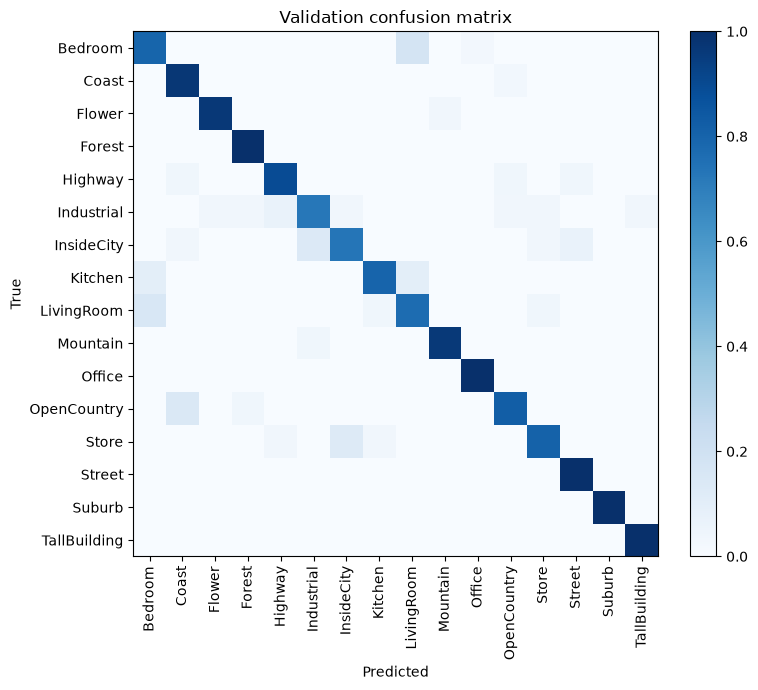

In [13]:
import numpy as np
import matplotlib.pyplot as plt

@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def per_class_report(model, loader, class_names, device, title=''):
    preds, labels = get_predictions(model, loader, device)
    n = len(class_names)

    # Confusion matrix: rows = true class, cols = predicted class
    cm = np.zeros((n, n), dtype=int)
    for t, p in zip(labels, preds):
        cm[t, p] += 1

    support = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / np.maximum(support, 1)

    print(f'{title} overall accuracy: {(preds == labels).mean():.4f}\n')
    print(f'{"Class":<14}{"Acc":>7}{"N":>6}   Most confused with')
    for i in np.argsort(per_class_acc):  # worst classes first
        off = cm[i].copy()
        off[i] = 0
        confused = class_names[off.argmax()] if off.sum() > 0 else '-'
        print(f'{class_names[i]:<14}{per_class_acc[i]:>7.3f}{support[i]:>6}   {confused}')

    # Confusion matrix plot (row-normalized)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm / np.maximum(support[:, None], 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{title} confusion matrix')
    plt.colorbar(im, fraction=0.046)
    plt.tight_layout()
    plt.show()
    return cm, per_class_acc

# Use validation for analysis and decisions
cm_val, acc_val = per_class_report(model, val_loader, class_names, device, 'Validation')

# Test set only for the final reported model
# cm_test, acc_test = per_class_report(model, test_loader, class_names, device, 'Test')

In [14]:
# also evaluate on last state
model.load_state_dict(last_state)
test_loss, test_acc = evaluate(model, test_loader, device)
print(f'Final test loss: {test_loss:.4f}')
print(f'Final test accuracy: {test_acc:.4f}')

Final test loss: 0.5959
Final test accuracy: 0.8550


Validation overall accuracy: 0.8771

Class             Acc     N   Most confused with
InsideCity      0.633    30   Industrial
LivingRoom      0.692    26   Bedroom
OpenCountry     0.750    28   Coast
Industrial      0.793    29   Flower
Kitchen         0.800    30   Bedroom
Store           0.806    31   InsideCity
Bedroom         0.821    39   LivingRoom
Highway         0.929    28   Coast
Mountain        0.929    28   Flower
Forest          0.966    29   Store
Flower          0.968    31   Mountain
Street          0.969    32   Highway
Coast           0.970    33   OpenCountry
Office          1.000    24   -
Suburb          1.000    34   -
TallBuilding    1.000    28   -


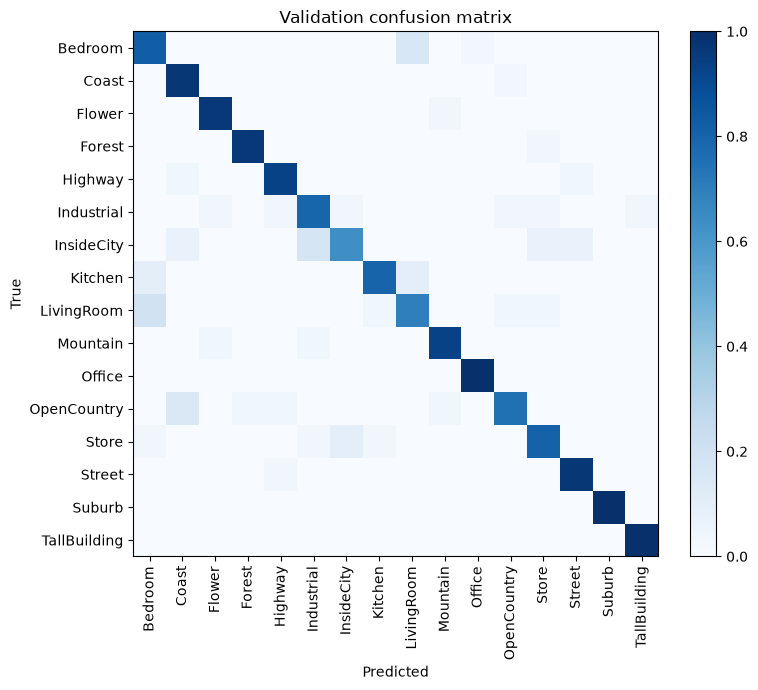

In [15]:
import numpy as np
import matplotlib.pyplot as plt

@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        logits = model(images.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def per_class_report(model, loader, class_names, device, title=''):
    preds, labels = get_predictions(model, loader, device)
    n = len(class_names)

    # Confusion matrix: rows = true class, cols = predicted class
    cm = np.zeros((n, n), dtype=int)
    for t, p in zip(labels, preds):
        cm[t, p] += 1

    support = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / np.maximum(support, 1)

    print(f'{title} overall accuracy: {(preds == labels).mean():.4f}\n')
    print(f'{"Class":<14}{"Acc":>7}{"N":>6}   Most confused with')
    for i in np.argsort(per_class_acc):  # worst classes first
        off = cm[i].copy()
        off[i] = 0
        confused = class_names[off.argmax()] if off.sum() > 0 else '-'
        print(f'{class_names[i]:<14}{per_class_acc[i]:>7.3f}{support[i]:>6}   {confused}')

    # Confusion matrix plot (row-normalized)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm / np.maximum(support[:, None], 1), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(n)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{title} confusion matrix')
    plt.colorbar(im, fraction=0.046)
    plt.tight_layout()
    plt.show()
    return cm, per_class_acc

# Use validation for analysis and decisions
cm_val, acc_val = per_class_report(model, val_loader, class_names, device, 'Validation')

# Test set only for the final reported model
# cm_test, acc_test = per_class_report(model, test_loader, class_names, device, 'Test')